# Machine Learning for Public Procurement Transparency

**Task:** Predict the procurement category recorded in a World Bank procurement notice from its description.

**Input:** Bid Description  
**Target:** Procurement Category  
**Classes:** Consultant Services, Goods, Non-consulting Services, and Works

## Project Overview

This project investigates whether machine learning can predict procurement categories from World Bank procurement notice descriptions.

The target categories are Consultant Services, Goods, Non-consulting Services, and Works.

This project connects to my personal mission of contributing to stronger governance and infrastructure in Nigeria. By exploring how procurement information can be automatically classified, the project investigates one possible way to make public procurement information easier to organize and analyze.

The model predicts the procurement category recorded in a notice. It does not directly detect corruption, measure government effectiveness, or determine whether an infrastructure project succeeds.

## Notebook Roadmap

1. Dataset and preparation
2. Exploratory data analysis
3. Data splitting and leakage prevention
4. Traditional models and controlled experiments
5. Deep-learning experiments
6. Validation experiment summary
7. Held-out test evaluation and ROC-AUC
8. Nigeria-specific analysis
9. Final model comparison
10. Limitations and future improvements

**Reproducibility note:** Run the notebook from top to bottom in Google Colab. The first code cell mounts Google Drive and loads the original CSV directly from `procurement_notice_10-11-2026.zip` in the project folder; if that ZIP is not found, it prompts for a CSV upload. The notebook uses fixed random seeds and a project-group split; model outputs may vary slightly across library versions or hardware.


In [ ]:
import os
import zipfile
import pandas as pd
from google.colab import drive, files

# Mount Google Drive so the notebook can load the zipped dataset.
drive.mount('/content/drive')

project_folder = (
    '/content/drive/MyDrive/'
    'Procurement Category Classification - ML Project'
)
zip_path = os.path.join(project_folder, 'procurement_notice_10-11-2026.zip')

if os.path.exists(zip_path):
    # Read the CSV directly from the ZIP without extracting another copy.
    with zipfile.ZipFile(zip_path, 'r') as zf:
        csv_files = [name for name in zf.namelist() if name.lower().endswith('.csv')]
        if not csv_files:
            raise FileNotFoundError('The ZIP archive contains no CSV file.')
        if len(csv_files) > 1:
            print('Multiple CSV files found; using:', csv_files[0])
        with zf.open(csv_files[0]) as csv_file:
            df = pd.read_csv(csv_file, low_memory=False)
    print('Loaded dataset from Google Drive ZIP:', zip_path)
else:
    # Fallback for users who do not have the ZIP in the expected Drive folder.
    print('Dataset ZIP not found in the expected Drive folder. Upload the CSV file.')
    uploaded = files.upload()
    if not uploaded:
        raise FileNotFoundError('No CSV file was uploaded.')
    filename = next(iter(uploaded))
    df = pd.read_csv(filename, low_memory=False)
    print('Loaded uploaded file:', filename)

print('Dataset loaded successfully!')
print('Rows:', f'{df.shape[0]:,}')
print('Columns:', df.shape[1])
print('\nColumn names:')
print(df.columns.tolist())
print('\nFirst five rows:')
display(df.head())


Mounted at /content/drive
Loaded dataset from Google Drive ZIP: /content/drive/MyDrive/Procurement Category Classification - ML Project/procurement_notice_10-11-2026.zip
Dataset loaded successfully!
Rows: 421,584
Columns: 15

Column names:
['ID', 'URL', 'Notice Type', 'Publication Date', 'Project ID', 'Bid Description', 'Procurement Category', 'Procurement Method', 'Deadline Date', 'Country Code', 'Country Name', 'Region', 'Sector', 'Publication - Fiscal year', 'Publication - Calendar year']

First five rows:


,ID,URL,Notice Type,Publication Date,Project ID,Bid Description,Procurement Category,Procurement Method,Deadline Date,Country Code,Country Name,Region,Sector,Publication - Fiscal year,Publication - Calendar year
0,5,https://projects.worldbank.org/en/projects-ope...,Invitation for Bids,09/16/2005,P006010,ADQUISICION DE EQUIPOS DE LABORATORIO,NaN,International Competitive Bidding,09/16/2005,AR,Argentina,Latin America And Caribbean,Roads and highways;Water Supply;Other Agricult...,2006,2005
1,6,https://projects.worldbank.org/en/projects-ope...,Request for Expression of Interest,09/26/2005,P082627,IMPLEMENTATION ASSISTANCE,NaN,Quality And Cost-Based Selection,09/26/2005,VN,Vietnam,East Asia And Pacific,Banking Institutions;Other Non-bank Financial ...,2006,2005
2,7,https://projects.worldbank.org/en/projects-ope...,Request for Expression of Interest,09/26/2005,P082627,IMPLEMENTATION ASSISTANCE,NaN,Quality And Cost-Based Selection,09/26/2005,VN,Vietnam,East Asia And Pacific,Banking Institutions;Other Non-bank Financial ...,2006,2005
3,8,https://projects.worldbank.org/en/projects-ope...,Request for Expression of Interest,09/26/2005,P082627,IMPLEMENTATION ASSISTANCE,NaN,Quality And Cost-Based Selection,09/26/2005,VN,Vietnam,East Asia And Pacific,Banking Institutions;Other Non-bank Financial ...,2006,2005
4,9,https://projects.worldbank.org/en/projects-ope...,Request for Expression of Interest,09/26/2005,P082627,IMPLEMENTATION CONSULTANT,NaN,Quality And Cost-Based Selection,09/26/2005,VN,Vietnam,East Asia And Pacific,Banking Institutions;Other Non-bank Financial ...,2006,2005


## 2. Dataset and Data Preparation

This project uses the World Bank Procurement Notice dataset, which contains procurement notices from different countries and projects.

The original dataset contains approximately 421,584 records. After cleaning and filtering, approximately 384,722 records were available for modeling.

The input feature is the procurement notice description. The target variable is the recorded procurement category, with four classes: Consultant Services, Goods, Non-consulting Services, and Works.

The dataset is divided into training, validation, and test sets using Project ID to reduce the risk of information leakage between projects. The training set is used to fit the models, the validation set supports model comparison, and the test set evaluates performance on held-out data.

TF-IDF is used to represent text for the traditional machine-learning models, while the deep-learning models use text vectorization and embedding layers.

In [ ]:
import pandas as pd

# 1. Check missing values and unique values
print("DATA QUALITY")
quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})
display(quality)

# 2. Inspect possible classification targets
target_candidates = [
    "Notice Type",
    "Procurement Category",
    "Procurement Method",
    "Sector",
    "Region",
    "Country Name"
]

print("\nTARGET CANDIDATE DISTRIBUTIONS")
for col in target_candidates:
    if col in df.columns:
        print("\n" + "=" * 55)
        print(col)
        print("Non-missing rows:", df[col].notna().sum())
        print("Number of classes:", df[col].nunique(dropna=True))
        print(df[col].value_counts(dropna=False).head(20))

# 3. Check Nigeria's representation
nigeria = df[
    df["Country Name"].astype("string").str.strip().str.casefold()
    == "nigeria"
].copy()

print("\n" + "=" * 55)
print("NIGERIA DATA CHECK")
print("Nigeria rows:", f"{len(nigeria):,}")

if not nigeria.empty:
    print("\nNigeria notice types:")
    print(nigeria["Notice Type"].value_counts(dropna=False))

    print("\nNigeria procurement categories:")
    print(nigeria["Procurement Category"].value_counts(dropna=False))

    print("\nNigeria procurement methods:")
    print(nigeria["Procurement Method"].value_counts(dropna=False))

# 4. Check duplicate records
print("\nDuplicate complete rows:", df.duplicated().sum())
print("Unique notice IDs:", df["ID"].nunique())

DATA QUALITY


,missing_count,missing_percent,unique_values
ID,0,0.00,421584
URL,0,0.00,421584
Notice Type,0,0.00,7
Publication Date,0,0.00,6547
Project ID,0,0.00,6163
Bid Description,6228,1.48,271634
Procurement Category,36862,8.74,4
Procurement Method,6226,1.48,23
Deadline Date,0,0.00,6659
Country Code,54154,12.85,142



TARGET CANDIDATE DISTRIBUTIONS

Notice Type
Non-missing rows: 421584
Number of classes: 7
Notice Type
Contract Award                        311010
Request for Expression of Interest     60670
Invitation for Bids                    45753
General Procurement Notice              3416
Invitation for Prequalification          731
Small Contracts Award                      2
Goods and Works Award                      2
Name: count, dtype: int64

Procurement Category
Non-missing rows: 384722
Number of classes: 4
Procurement Category
Consultant Services        156999
Goods                      116194
Works                       83734
NaN                         36862
Non-consulting Services     27795
Name: count, dtype: int64

Procurement Method
Non-missing rows: 415358
Number of classes: 23
Procurement Method
Request for Quotations                 120132
Individual Consultant Selection         89336
Request for Bids                        85793
Direct Selection                        37909
Q

## 3. Exploratory Data Analysis

Exploratory Data Analysis (EDA) helps us understand the structure and characteristics of the dataset before training machine-learning models.

In this project, EDA focuses on the distribution of procurement categories, the number of available records, and possible class imbalance.

The dataset contains four procurement categories. Differences in the number of examples per category may affect model performance, so the evaluation will examine precision, recall, and F1 score for each class rather than relying on accuracy alone.

The findings from this section will help explain the models' strengths and weaknesses, especially for less frequent procurement categories.

In [ ]:
import pandas as pd

# Keep records with a known target and a usable description
model_df = df.dropna(
    subset=["Procurement Category", "Bid Description"]
).copy()

# Clean whitespace
model_df["Procurement Category"] = (
    model_df["Procurement Category"].astype(str).str.strip()
)
model_df["Bid Description"] = (
    model_df["Bid Description"].astype(str).str.strip()
)

# Remove empty descriptions and empty target labels
model_df = model_df[
    (model_df["Bid Description"] != "") &
    (model_df["Procurement Category"] != "")
].copy()

print("Usable records:", f"{len(model_df):,}")
print("\nTarget class counts:")
print(model_df["Procurement Category"].value_counts())

print("\nTarget class percentages:")
print(
    (model_df["Procurement Category"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nSample descriptions by category:")
for category in model_df["Procurement Category"].unique():
    print(f"\n--- {category} ---")
    print(
        model_df.loc[
            model_df["Procurement Category"] == category,
            "Bid Description"
        ].head(3).to_string(index=False)
    )

print("\nUnique projects:", model_df["Project ID"].nunique())
print("Unique descriptions:", model_df["Bid Description"].nunique())

Usable records: 384,722

Target class counts:
Procurement Category
Consultant Services        156999
Goods                      116194
Works                       83734
Non-consulting Services     27795
Name: count, dtype: int64

Target class percentages:
Procurement Category
Consultant Services        40.81
Goods                      30.20
Works                      21.76
Non-consulting Services     7.22
Name: proportion, dtype: float64

Sample descriptions by category:

--- Works ---
CONSTRUCTION OF THE MULTIPURPOSE/CONTAINER TERM...
       CIVIL WORKS FOR COMPLETION OF LUDA YANA DAM
Design, Build And Operate Of Ahwaz Eastern Wast...

--- Goods ---
Laboratory equipment for phyto-sanitary laborat...
PROCUREMENT OF 142,000 SETS OF ELASTIC CLAMPS T...
PROCUREMENT OF 1,660 PCS - CONCRETE SLEEPERS TY...

--- Consultant Services ---
          Public awareness compaign implementation
CONTRATO DE CONSULTORÍA PARA  REALIZAR LAS  TAR...
CONSULTANCY SERVICES FOR FULL FEASIBILITY STUDY...

--- N

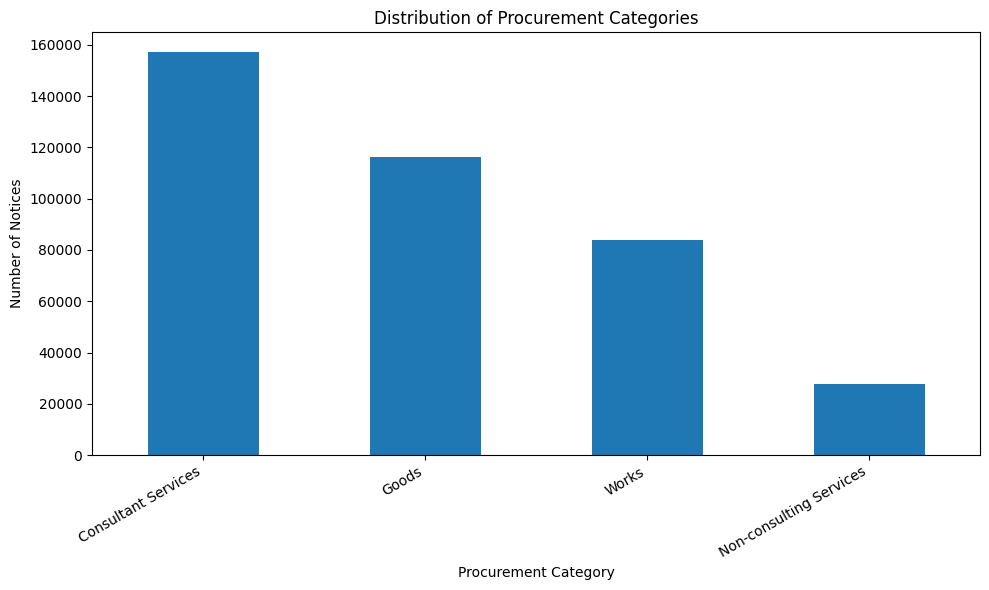

,Number of Notices,Percentage (%)
Procurement Category,,
Consultant Services,156999,40.81
Goods,116194,30.20
Works,83734,21.76
Non-consulting Services,27795,7.22


In [ ]:
import matplotlib.pyplot as plt

# Count records in each procurement category
class_counts = model_df["Procurement Category"].value_counts()

# Create the chart
plt.figure(figsize=(10, 6))
class_counts.plot(kind="bar")

plt.title("Distribution of Procurement Categories")
plt.xlabel("Procurement Category")
plt.ylabel("Number of Notices")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Display the counts and percentages
class_summary = pd.DataFrame({
    "Number of Notices": class_counts,
    "Percentage (%)": (
        model_df["Procurement Category"]
        .value_counts(normalize=True) * 100
    ).round(2)
})

display(class_summary)

### 3.2 Project Structure, Description Quality, and Nigeria Subset

This analysis examines how procurement notices are distributed across projects, whether individual projects contain multiple procurement categories, and whether identical descriptions are associated with different category labels.

These checks help identify potential challenges for text classification. If identical descriptions have different labels, the description alone may not always provide enough information to predict the correct category.

The analysis also examines procurement notices associated with Nigeria. This provides a country-specific perspective that can be compared with the worldwide results, while recognizing that the Nigerian subset is smaller than the full dataset.

In [ ]:
# 1. How many records belong to each project?
project_sizes = model_df.groupby("Project ID").size()

print("PROJECT OVERVIEW")
print("Unique projects:", model_df["Project ID"].nunique())
print("Median notices per project:", project_sizes.median())
print("Largest project notice count:", project_sizes.max())
print("Projects with more than one notice:", (project_sizes > 1).sum())

# 2. Do projects contain multiple procurement categories?
categories_per_project = (
    model_df.groupby("Project ID")["Procurement Category"].nunique()
)

print("\nPROJECT CATEGORY MIX")
print("Projects with multiple categories:", (categories_per_project > 1).sum())
print(
    "Percentage of projects with multiple categories:",
    round((categories_per_project > 1).mean() * 100, 2), "%"
)

# 3. Are identical descriptions associated with different labels?
description_label_counts = (
    model_df.groupby("Bid Description")["Procurement Category"].nunique()
)

print("\nDESCRIPTION CHECK")
print("Unique descriptions:", model_df["Bid Description"].nunique())
print("Descriptions associated with multiple categories:",
      (description_label_counts > 1).sum())

# 4. Inspect repeated descriptions
repeated_descriptions = (
    model_df.groupby("Bid Description")
    .agg(
        records=("Procurement Category", "size"),
        categories=("Procurement Category", "nunique")
    )
    .query("records > 1")
    .sort_values("records", ascending=False)
)

print("\nMost repeated descriptions:")
display(repeated_descriptions.head(10))

# 5. Check procurement categories in Nigeria
nigeria_df = model_df[
    model_df["Country Name"].astype("string").str.strip().str.casefold()
    == "nigeria"
]

print("\nNIGERIA SUBSET")
print("Usable Nigeria records:", f"{len(nigeria_df):,}")
print("\nNigeria category counts:")
print(nigeria_df["Procurement Category"].value_counts())

print("\nNigeria category percentages:")
print(
    (nigeria_df["Procurement Category"].value_counts(normalize=True) * 100)
    .round(2)
)

PROJECT OVERVIEW
Unique projects: 4110
Median notices per project: 35.0
Largest project notice count: 15532
Projects with more than one notice: 3784

PROJECT CATEGORY MIX
Projects with multiple categories: 3252
Percentage of projects with multiple categories: 79.12 %

DESCRIPTION CHECK
Unique descriptions: 243586
Descriptions associated with multiple categories: 112

Most repeated descriptions:


,records,categories
Bid Description,,
Procurement Specialist,528,1
Data Collection: Enumerators (PHC),378,1
Contratación de 100 Enumeradores,368,1
Service Provider,313,1
Financial Management Specialist,282,1
Procurement Officer,254,1
Field operation Enumerators,228,1
Project Coordinator,208,1
Procurement of goods for adaptation to the implementation of WDS,201,1



NIGERIA SUBSET
Usable Nigeria records: 10,739

Nigeria category counts:
Procurement Category
Goods                      3836
Consultant Services        3724
Works                      2789
Non-consulting Services     390
Name: count, dtype: int64

Nigeria category percentages:
Procurement Category
Goods                      35.72
Consultant Services        34.68
Works                      25.97
Non-consulting Services     3.63
Name: proportion, dtype: float64


### 3.3 Findings from Project and Description Analysis

The dataset contains 4,110 unique projects, with a median of 35 notices per project. A total of 3,784 projects contain more than one notice, and the largest project contains 15,532 notices.

The analysis shows that 3,252 projects, representing 79.12% of all projects, contain multiple procurement categories. This demonstrates that a single project may involve different types of procurement. Therefore, the project itself does not necessarily determine the category of an individual notice.

There are 243,586 unique procurement descriptions. Of these, 112 descriptions are associated with more than one procurement category. This indicates that identical descriptions can sometimes have different labels, making classification based on description text alone more challenging. Repeated descriptions should also be considered when evaluating how well the models generalize to unfamiliar examples.

The Nigeria subset contains 10,739 usable notices. Goods account for 35.72%, Consultant Services for 34.68%, Works for 25.97%, and Non-consulting Services for 3.63%.

The Nigerian subset has a different category distribution from the worldwide dataset. Non-consulting Services is particularly uncommon in the Nigerian subset. This imbalance is important when interpreting country-specific evaluation results, especially precision, recall, and F1 score.

These findings motivate the use of project-aware data splitting, class-specific evaluation metrics, and additional error analysis. The Nigerian subset contains fewer than 20,000 usable records, so the worldwide dataset remains the main dataset for this project.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit
import pandas as pd

# Reset the index so positional split indices are easy to use
data = model_df.reset_index(drop=True).copy()

X_text = data["Bid Description"]
y = data["Procurement Category"]
groups = data["Project ID"]

# First split: 85% development data, 15% final test data
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

trainval_idx, test_idx = next(
    split1.split(X_text, y, groups=groups)
)

# Second split: divide development data into training and validation
# 0.1765 of 85% is approximately 15% of the full dataset
development = data.iloc[trainval_idx]

split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.1765,
    random_state=42
)

train_rel, val_rel = next(
    split2.split(
        development["Bid Description"],
        development["Procurement Category"],
        groups=development["Project ID"]
    )
)

train_idx = trainval_idx[train_rel]
val_idx = trainval_idx[val_rel]

train_df = data.iloc[train_idx].copy()
val_df = data.iloc[val_idx].copy()
test_df = data.iloc[test_idx].copy()

# Show dataset sizes
print("SPLIT SIZES")
for name, part in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"{name}: {len(part):,} rows ({len(part)/len(data)*100:.2f}%)")

# Verify that projects do not overlap between splits
train_projects = set(train_df["Project ID"])
val_projects = set(val_df["Project ID"])
test_projects = set(test_df["Project ID"])

print("\nPROJECT OVERLAP CHECK")
print("Train/validation overlap:", len(train_projects & val_projects))
print("Train/test overlap:", len(train_projects & test_projects))
print("Validation/test overlap:", len(val_projects & test_projects))

# Check whether all classes are represented in each split
print("\nCLASS DISTRIBUTION BY SPLIT")
for name, part in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name} class percentages:")
    print(
        (part["Procurement Category"].value_counts(normalize=True) * 100)
        .round(2)
    )
    print("Class counts:")
    print(part["Procurement Category"].value_counts())

# Check Nigeria's representation in each split
print("\nNIGERIA RECORDS BY SPLIT")
for name, part in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    count = (
        part["Country Name"].astype("string").str.strip().str.casefold()
        == "nigeria"
    ).sum()
    print(f"{name}: {count:,} Nigeria records")

SPLIT SIZES
Training: 276,855 rows (71.96%)
Validation: 47,985 rows (12.47%)
Test: 59,882 rows (15.57%)

PROJECT OVERLAP CHECK
Train/validation overlap: 0
Train/test overlap: 0
Validation/test overlap: 0

CLASS DISTRIBUTION BY SPLIT

Training class percentages:
Procurement Category
Consultant Services        40.57
Goods                      30.13
Works                      22.77
Non-consulting Services     6.52
Name: proportion, dtype: float64
Class counts:
Procurement Category
Consultant Services        112325
Goods                       83424
Works                       63048
Non-consulting Services     18058
Name: count, dtype: int64

Validation class percentages:
Procurement Category
Consultant Services        42.95
Goods                      31.10
Works                      16.66
Non-consulting Services     9.29
Name: proportion, dtype: float64
Class counts:
Procurement Category
Consultant Services        20610
Goods                      14921
Works                       7994
Non-

## 4. Traditional Machine Learning Experiments

This section evaluates traditional machine-learning methods for predicting procurement categories from notice descriptions.

A majority-class baseline provides a reference point by predicting the most frequent category. Logistic Regression is then trained using TF-IDF features, which represent text descriptions numerically according to the importance of words.

The models are evaluated using accuracy, macro F1, and weighted F1. Accuracy measures the proportion of correct predictions. Macro F1 calculates the average F1 score across the four categories with equal weight for each class, while weighted F1 accounts for the number of examples in each category.

The validation results are used to compare model performance before final evaluation on the held-out test set.

### 4.1 Baseline and Logistic Regression Results




In [ ]:
import time
import numpy as np
import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    f1_score
)

# Prepare features and labels
X_train = train_df["Bid Description"].fillna("").astype(str)
y_train = train_df["Procurement Category"]

X_val = val_df["Bid Description"].fillna("").astype(str)
y_val = val_df["Procurement Category"]

X_test = test_df["Bid Description"].fillna("").astype(str)
y_test = test_df["Procurement Category"]

labels = sorted(y_train.unique())

# 1. Majority-class baseline
baseline = DummyClassifier(strategy="most_frequent")

start = time.time()
baseline.fit(X_train, y_train)
baseline_val_pred = baseline.predict(X_val)
baseline_time = time.time() - start

# 2. TF-IDF + Logistic Regression
logistic_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=(1, 2),
            min_df=3,
            max_features=100000,
            sublinear_tf=True,
            dtype=np.float32
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            solver="lbfgs",
            random_state=42
        )
    )
])

start = time.time()
logistic_model.fit(X_train, y_train)
logistic_time = time.time() - start

logistic_val_pred = logistic_model.predict(X_val)

# Compare validation results
results = pd.DataFrame([
    {
        "Model": "Majority baseline",
        "Accuracy": accuracy_score(y_val, baseline_val_pred),
        "Macro F1": f1_score(
            y_val, baseline_val_pred,
            labels=labels, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_val, baseline_val_pred,
            average="weighted", zero_division=0
        ),
        "Training seconds": round(baseline_time, 2)
    },
    {
        "Model": "TF-IDF + Logistic Regression",
        "Accuracy": accuracy_score(y_val, logistic_val_pred),
        "Macro F1": f1_score(
            y_val, logistic_val_pred,
            labels=labels, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_val, logistic_val_pred,
            average="weighted", zero_division=0
        ),
        "Training seconds": round(logistic_time, 2)
    }
])

display(results.round(4))

print("\nLOGISTIC REGRESSION: VALIDATION REPORT")
print(classification_report(
    y_val,
    logistic_val_pred,
    labels=labels,
    zero_division=0
))

,Model,Accuracy,Macro F1,Weighted F1,Training seconds
0,Majority baseline,0.4295,0.1502,0.2581,0.20
1,TF-IDF + Logistic Regression,0.8994,0.8554,0.9015,66.19



LOGISTIC REGRESSION: VALIDATION REPORT
                         precision    recall  f1-score   support

    Consultant Services       0.96      0.93      0.95     20610
                  Goods       0.93      0.91      0.92     14921
Non-consulting Services       0.63      0.74      0.68      4460
                  Works       0.86      0.89      0.88      7994

               accuracy                           0.90     47985
              macro avg       0.85      0.87      0.86     47985
           weighted avg       0.90      0.90      0.90     47985



The majority-class baseline achieved a validation accuracy of 42.95%, a macro F1 score of 0.1502, and a weighted F1 score of 0.2581.

TF-IDF combined with Logistic Regression achieved a validation accuracy of 89.94%, a macro F1 score of 0.8554, and a weighted F1 score of 0.9015. Training took approximately 69.68 seconds.

These results show a substantial improvement over the baseline. However, performance differs across procurement categories. The class-specific F1 scores indicate that some categories are more difficult to classify than others, highlighting the importance of examining precision, recall, and F1 scores alongside overall accuracy.

### 4.2 Multiclass ROC-AUC Evaluation

ROC-AUC evaluates how well the model ranks examples of each procurement category against the other categories across classification thresholds. Macro ROC-AUC gives each category equal weight, while weighted ROC-AUC accounts for category frequency. These are validation metrics used during model analysis; they are not accuracy scores.

Validation Macro ROC-AUC: 0.9764
Validation Weighted ROC-AUC: 0.9845


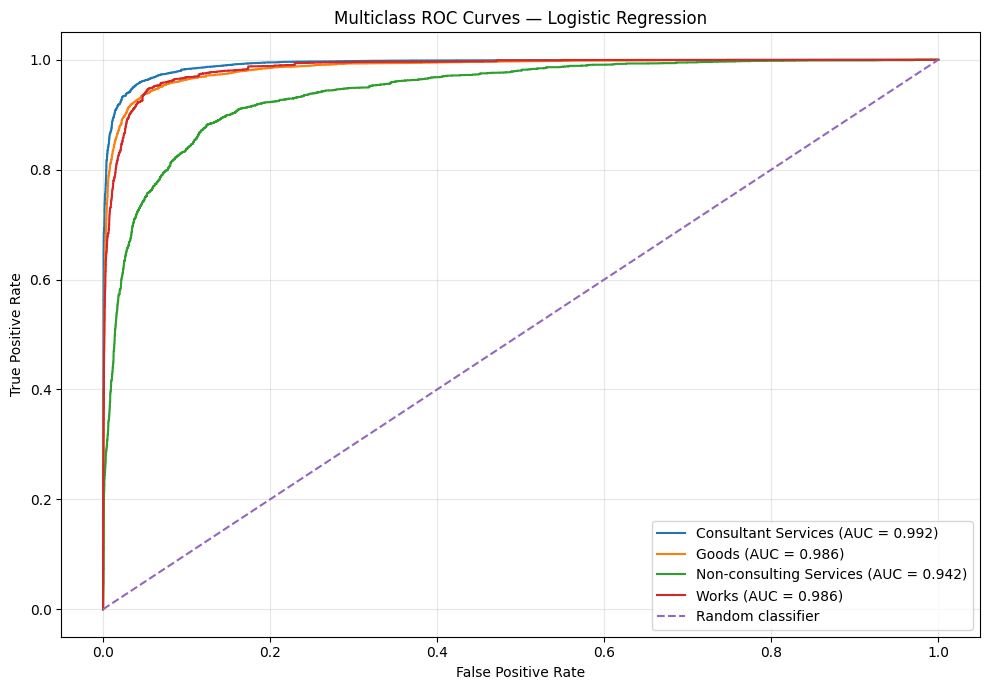

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    auc
)
from sklearn.preprocessing import label_binarize

# Get predicted probabilities for each procurement category
y_val_prob = logistic_model.predict_proba(X_val)
classes = logistic_model.classes_

# Convert the true labels into a one-vs-rest binary format
y_val_binary = label_binarize(y_val, classes=classes)

# Calculate multiclass ROC-AUC
macro_roc_auc = roc_auc_score(
    y_val,
    y_val_prob,
    labels=classes,
    multi_class="ovr",
    average="macro"
)

weighted_roc_auc = roc_auc_score(
    y_val,
    y_val_prob,
    labels=classes,
    multi_class="ovr",
    average="weighted"
)

print(f"Validation Macro ROC-AUC: {macro_roc_auc:.4f}")
print(f"Validation Weighted ROC-AUC: {weighted_roc_auc:.4f}")

# Plot a separate ROC curve for each category
plt.figure(figsize=(10, 7))

for i, category in enumerate(classes):
    fpr, tpr, _ = roc_curve(
        y_val_binary[:, i],
        y_val_prob[:, i]
    )

    category_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{category} (AUC = {category_auc:.3f})"
    )

# Reference line for random classification
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves — Logistic Regression")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Validation ROC-AUC result:** The balanced Logistic Regression model achieved macro one-vs-rest ROC-AUC of **0.9764** and weighted one-vs-rest ROC-AUC of **0.9845**. These values indicate strong class-ranking ability across thresholds; they are not classification accuracy. The test-set ROC-AUC results are calculated separately in Section 7.6 after model selection.

In [ ]:
import time
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Compare two TF-IDF feature configurations
tfidf_experiments = [
    {
        "Experiment": "Unigrams only",
        "ngram_range": (1, 1)
    },
    {
        "Experiment": "Unigrams + bigrams",
        "ngram_range": (1, 2)
    }
]

tfidf_results = []
tfidf_experiment_models = {}

for experiment in tfidf_experiments:
    name = experiment["Experiment"]

    # Use the same classifier settings for a fair comparison
    experiment_model = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                lowercase=True,
                strip_accents="unicode",
                ngram_range=experiment["ngram_range"],
                min_df=3,
                max_features=100000,
                sublinear_tf=True,
                dtype=np.float32
            )
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                solver="lbfgs",
                random_state=42
            )
        )
    ])

    start = time.time()
    experiment_model.fit(X_train, y_train)
    training_seconds = time.time() - start

    val_predictions = experiment_model.predict(X_val)

    tfidf_experiment_models[name] = experiment_model

    tfidf_results.append({
        "Experiment": name,
        "Accuracy": accuracy_score(y_val, val_predictions),
        "Macro F1": f1_score(
            y_val, val_predictions,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_val, val_predictions,
            average="weighted",
            zero_division=0
        ),
        "Training seconds": round(training_seconds, 2)
    })

tfidf_comparison = pd.DataFrame(tfidf_results)

display(
    tfidf_comparison.style.format({
        "Accuracy": "{:.2%}",
        "Macro F1": "{:.2%}",
        "Weighted F1": "{:.2%}",
        "Training seconds": "{:.2f}"
    })
)

,Experiment,Accuracy,Macro F1,Weighted F1,Training seconds
0,Unigrams only,89.39%,85.02%,89.69%,51.03
1,Unigrams + bigrams,89.94%,85.54%,90.15%,66.36


### 4.3 Controlled Experiment: TF-IDF N-gram Features

This experiment compares Logistic Regression using unigram features with Logistic Regression using both unigrams and bigrams, keeping the other model settings consistent.

The unigram-only model achieved a validation accuracy of 89.39%, macro F1 of 0.8502, and weighted F1 of 0.8969. Its training time was 51.03 seconds. The unigram-and-bigram model achieved 89.94% accuracy, macro F1 of 0.8554, and weighted F1 of 0.9015, with a training time of 66.36 seconds.

Adding bigrams improved accuracy by 0.55 percentage points and macro F1 by 0.52 percentage points, at an additional 10.73 seconds of training time. These validation results suggest that two-word combinations provide useful context for classifying procurement descriptions.


### 4.4 Controlled Experiment: Class Weighting

This experiment compares Logistic Regression with no class weighting against `class_weight="balanced"`. The aim is to examine the trade-off between overall accuracy and performance on less frequent categories.

In [ ]:
import time
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

class_weight_results = []
class_weight_models = {}

for weight_setting in [None, "balanced"]:
    model_name = (
        "Without class weights"
        if weight_setting is None
        else "With balanced class weights"
    )

    model = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=(1, 2),
            min_df=3,
            max_features=100000,
            sublinear_tf=True,
            dtype=np.float32
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight=weight_setting,
            solver="lbfgs",
            random_state=42
        ))
    ])

    start = time.time()
    model.fit(X_train, y_train)
    training_seconds = time.time() - start

    predictions = model.predict(X_val)

    class_weight_models[model_name] = model

    class_weight_results.append({
        "Experiment": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_val, predictions,
            average="weighted",
            zero_division=0
        ),
        "Training seconds": round(training_seconds, 2)
    })

class_weight_comparison = pd.DataFrame(class_weight_results)

display(
    class_weight_comparison.style.format({
        "Accuracy": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "Training seconds": "{:.2f}"
    })
)

,Experiment,Accuracy,Macro F1,Weighted F1,Training seconds
0,Without class weights,0.9007,0.8423,0.8957,67.56
1,With balanced class weights,0.8994,0.8554,0.9015,63.70


#### 4.4.1 Class-Level Results for the Weighting Experiment

The classification reports below show how precision, recall, and F1-score change for each procurement category.

In [ ]:
from sklearn.metrics import classification_report

for name, model in class_weight_models.items():
    predictions = model.predict(X_val)

    print(f"\n{name}")
    print(classification_report(
        y_val,
        predictions,
        zero_division=0
    ))


Without class weights
                         precision    recall  f1-score   support

    Consultant Services       0.92      0.97      0.94     20610
                  Goods       0.91      0.93      0.92     14921
Non-consulting Services       0.80      0.52      0.63      4460
                  Works       0.87      0.88      0.88      7994

               accuracy                           0.90     47985
              macro avg       0.87      0.83      0.84     47985
           weighted avg       0.90      0.90      0.90     47985


With balanced class weights
                         precision    recall  f1-score   support

    Consultant Services       0.96      0.93      0.95     20610
                  Goods       0.93      0.91      0.92     14921
Non-consulting Services       0.63      0.74      0.68      4460
                  Works       0.86      0.89      0.88      7994

               accuracy                           0.90     47985
              macro avg       0.8

### 4.4.2 Confusion Matrices: Class-Weight Comparison

The following comparison uses the **validation set** to show how class weighting changes correct and incorrect predictions for each category. It is part of model selection, so the test set is not used here. Rows are true categories and columns are predicted categories.

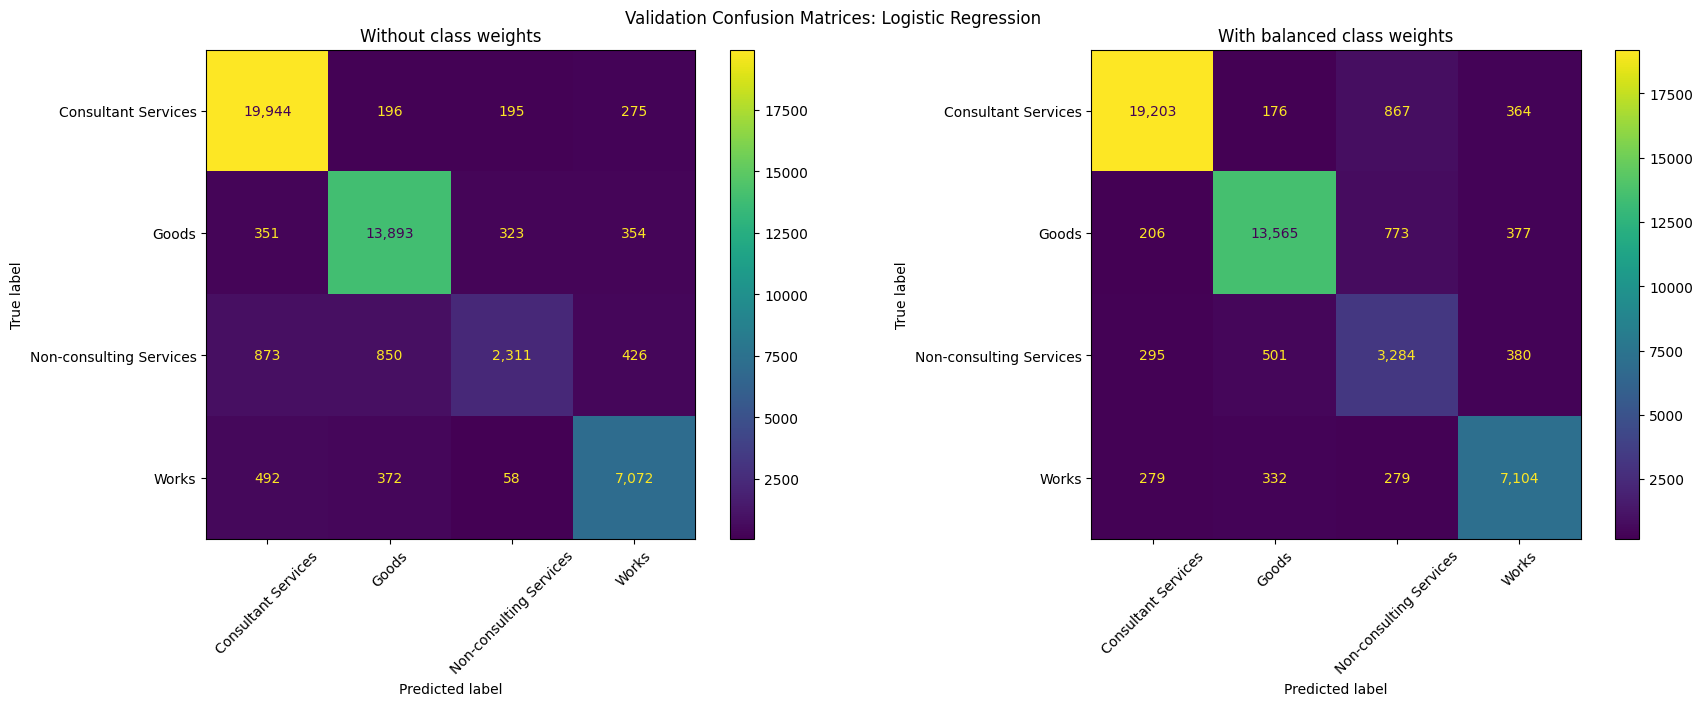

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
weight_order = ["Without class weights", "With balanced class weights"]

for ax, name in zip(axes, weight_order):
    fitted_model = class_weight_models[name]
    val_predictions = fitted_model.predict(X_val)
    cm = confusion_matrix(y_val, val_predictions, labels=labels)
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[str(label) for label in labels]
    ).plot(ax=ax, xticks_rotation=45, values_format=",")
    ax.set_title(name)

plt.suptitle("Validation Confusion Matrices: Logistic Regression")
plt.tight_layout()
plt.show()

Two additional traditional machine-learning models are evaluated using the TF-IDF representations created from the training descriptions.

Multinomial Naive Bayes is a probabilistic classifier that estimates the likely category of a description from its word features. Linear Support Vector Classification (Linear SVM) learns decision boundaries that separate the procurement categories.

Both models are trained on the training set and evaluated on the validation set. Their results are compared with the baseline and Logistic Regression using accuracy, macro F1, weighted F1, and training time. Class-specific precision and recall are also examined because overall metrics can hide weaker performance on less frequent categories.


### 4.5 Multinomial Naive Bayes and Linear SVM

These models provide additional traditional machine-learning comparisons using TF-IDF text features.

In [ ]:
import time
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Reuse the TF-IDF vectorizer already fitted on training descriptions
tfidf = logistic_model.named_steps["tfidf"]

X_train_tfidf = tfidf.transform(X_train)
X_val_tfidf = tfidf.transform(X_val)

# Define the models
models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.5),
    "Linear SVM": LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=42,
        max_iter=3000
    )
}

traditional_results = []
trained_models = {}

for name, model in models.items():
    print(f"\nTraining {name}...")
    start = time.time()

    model.fit(X_train_tfidf, y_train)
    predictions = model.predict(X_val_tfidf)

    elapsed = time.time() - start
    trained_models[name] = model

    traditional_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro F1": f1_score(
            y_val, predictions, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_val, predictions, average="weighted", zero_division=0
        ),
        "Training seconds": round(elapsed, 2)
    })

    print(f"\n{name} classification report:")
    print(classification_report(
        y_val, predictions, zero_division=0
    ))

# Compare with Logistic Regression and the baseline
comparison = pd.concat([
    results,
    pd.DataFrame(traditional_results)
], ignore_index=True)

display(
    comparison.sort_values("Macro F1", ascending=False).round(4)
)


Training Multinomial Naive Bayes...

Multinomial Naive Bayes classification report:
                         precision    recall  f1-score   support

    Consultant Services       0.86      0.98      0.92     20610
                  Goods       0.90      0.90      0.90     14921
Non-consulting Services       0.80      0.48      0.60      4460
                  Works       0.88      0.76      0.82      7994

               accuracy                           0.87     47985
              macro avg       0.86      0.78      0.81     47985
           weighted avg       0.87      0.87      0.86     47985


Training Linear SVM...

Linear SVM classification report:
                         precision    recall  f1-score   support

    Consultant Services       0.94      0.96      0.95     20610
                  Goods       0.92      0.93      0.93     14921
Non-consulting Services       0.70      0.64      0.67      4460
                  Works       0.89      0.89      0.89      7994

      

,Model,Accuracy,Macro F1,Weighted F1,Training seconds
3,Linear SVM,0.9071,0.8582,0.9060,121.36
1,TF-IDF + Logistic Regression,0.8994,0.8554,0.9015,66.19
2,Multinomial Naive Bayes,0.8717,0.8071,0.8645,0.81
0,Majority baseline,0.4295,0.1502,0.2581,0.20


### 4.6 Comparison of Traditional Machine Learning Models

The validation results show that Linear SVM achieved the strongest overall performance among the traditional models, with an accuracy of 90.71%, a macro F1 score of 0.8582, and a weighted F1 score of 0.9060. Its training time was approximately 99.98 seconds.

TF-IDF combined with Logistic Regression achieved an accuracy of 89.94%, a macro F1 score of 0.8554, and a weighted F1 score of 0.9015. Although its validation performance was slightly lower than Linear SVM, it required less training time, at approximately 66.19 seconds.

Multinomial Naive Bayes trained much faster, taking approximately 0.80 seconds, but achieved lower validation performance, with an accuracy of 87.17% and a macro F1 score of 0.8071. The majority-class baseline performed substantially worse than all three trained classifiers.

Class-specific results reveal an important limitation. For Non-consulting Services, Linear SVM achieved an F1 score of 0.67, compared with 0.68 for Logistic Regression and 0.60 for Naive Bayes. Therefore, the model with the highest overall validation accuracy does not necessarily perform best on every category.

Based on these validation results, Linear SVM is the leading traditional model by overall accuracy and macro F1. Logistic Regression remains a competitive alternative, particularly when considering the trade-off between predictive performance and training time.

## 5. Deep Learning Experiments

This section investigates whether neural networks can learn useful patterns from procurement notice descriptions and predict their procurement categories.

Unlike the traditional models, which use TF-IDF features, the neural networks use a TextVectorization layer to convert descriptions into sequences of token IDs. An embedding layer then learns numerical representations of words during training.

Two Keras models are evaluated. The first establishes an initial neural-network approach, while the second introduces additional regularization to help control overfitting.

The models are trained using the training data, and their performance is monitored on the validation data. The final regularized model is also evaluated on the held-out test set to measure its generalization performance.

### 5.1 Initial Neural Network: Embedding and Dense Layers

This experiment uses a neural network to classify procurement notices based on their bid descriptions.

The target labels are converted into integer values using LabelEncoder. A TextVectorization layer learns a vocabulary from the training descriptions and converts each description into a sequence of 100 token IDs, using a vocabulary limit of 30,000 tokens.

An embedding layer learns 128-dimensional representations of the tokens. Global average pooling combines these representations into a fixed-size feature vector. A dense layer with 128 neurons and ReLU activation learns patterns in the text, while a dropout rate of 0.4 helps reduce overfitting.

The output layer uses softmax activation to predict probabilities for the four procurement categories. The model is trained using the Adam optimizer and sparse categorical cross-entropy loss.

Class weights are calculated from the training labels to account for differences in class frequencies. Early stopping monitors validation loss and restores the weights from the best-performing epoch.

The model is evaluated on the validation set using accuracy, macro F1, weighted F1, and a classification report. These results provide a baseline for comparison with the more regularized neural network.

In [ ]:
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Reproducibility
tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())

# 1. Encode the four category labels as integers
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)

num_classes = len(label_encoder.classes_)

print("\nClass mapping:")
for i, name in enumerate(label_encoder.classes_):
    print(i, "=", name)

# 2. Build a text vectorizer using training descriptions only
MAX_TOKENS = 30000
SEQUENCE_LENGTH = 100
BATCH_SIZE = 256

vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH,
    standardize="lower_and_strip_punctuation"
)

train_text_ds = tf.data.Dataset.from_tensor_slices(
    X_train.to_numpy()
).batch(1024)

vectorizer.adapt(train_text_ds)

vocab_size = len(vectorizer.get_vocabulary())
print("\nVocabulary size:", vocab_size)

# 3. Build efficient input pipelines
train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train.to_numpy(), y_train_encoded)
)
train_ds = train_ds.shuffle(
    20000, seed=42, reshuffle_each_iteration=True
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val.to_numpy(), y_val_encoded)
)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# 4. Account for class imbalance during training
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(num_classes),
    y=y_train_encoded
)

class_weights = {
    i: float(weight)
    for i, weight in enumerate(class_weights_array)
}

print("\nClass weights:", class_weights)

# 5. Build the neural network
text_input = tf.keras.Input(
    shape=(), dtype=tf.string, name="bid_description"
)

x = vectorizer(text_input)
x = tf.keras.layers.Embedding(
    input_dim=vocab_size,
    output_dim=128,
    mask_zero=True
)(x)
x = tf.keras.layers.GlobalAveragePooling1D()(x)
x = tf.keras.layers.Dense(128, activation="relu")(x)
x = tf.keras.layers.Dropout(0.4)(x)

output = tf.keras.layers.Dense(
    num_classes, activation="softmax"
)(x)

dl_model = tf.keras.Model(
    inputs=text_input,
    outputs=output
)

dl_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

dl_model.summary()

# 6. Train with early stopping
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )
]

start = time.time()

history = dl_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

training_seconds = time.time() - start
print(f"\nTraining time: {training_seconds:.2f} seconds")

# 7. Evaluate on validation data
val_probabilities = dl_model.predict(val_ds, verbose=1)
val_dl_predictions = np.argmax(val_probabilities, axis=1)

print("\nDEEP LEARNING VALIDATION REPORT")
print(classification_report(
    y_val_encoded,
    val_dl_predictions,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0
))

dl_results = pd.DataFrame([{
    "Model": "Keras Embedding + Dense",
    "Accuracy": accuracy_score(
        y_val_encoded, val_dl_predictions
    ),
    "Macro F1": f1_score(
        y_val_encoded,
        val_dl_predictions,
        average="macro",
        zero_division=0
    ),
    "Weighted F1": f1_score(
        y_val_encoded,
        val_dl_predictions,
        average="weighted",
        zero_division=0
    ),
    "Training seconds": round(training_seconds, 2)
}])

display(dl_results.round(4))

TensorFlow version: 2.21.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]

Class mapping:
0 = Consultant Services
1 = Goods
2 = Non-consulting Services
3 = Works

Vocabulary size: 30000

Class weights: {0: 0.6161918539951035, 1: 0.8296623273878021, 2: 3.832858013069, 3: 1.0977945374952418}


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ bid_description     │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 100)       │          0 │ bid_description[… │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 100, 128)  │  3,840,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 100)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ embedding[0][0],  │
│ (GlobalAveragePool… │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     16,512 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 4)         │        516 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,857,028 (14.71 MB)

 Trainable params: 3,857,028 (14.71 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 78s 71ms/step - accuracy: 0.9194 - loss: 0.3019 - val_accuracy: 0.8752 - val_loss: 0.3830
Epoch 2/10
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 76s 70ms/step - accuracy: 0.9575 - loss: 0.1499 - val_accuracy: 0.8785 - val_loss: 0.3951
Epoch 3/10
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 78s 72ms/step - accuracy: 0.9663 - loss: 0.1131 - val_accuracy: 0.8774 - val_loss: 0.4291

Training time: 235.88 seconds
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step

DEEP LEARNING VALIDATION REPORT
                         precision    recall  f1-score   support

    Consultant Services       0.97      0.90      0.94     20610
                  Goods       0.94      0.87      0.90     14921
Non-consulting Services       0.50      0.81      0.62      4460
                  Works       0.87      0.86      0.86      7994

               accuracy                           0.88     47985
              macro avg       0.82      0.86      0.83     47985
           weighted avg       0.90      0

,Model,Accuracy,Macro F1,Weighted F1,Training seconds
0,Keras Embedding + Dense,0.8752,0.8296,0.8839,235.88


### 5.2 Initial Neural Network: Results and Interpretation

The first deep-learning model combined a text embedding layer, global average pooling, and fully connected dense layers to classify procurement notices into four categories. The model used a vocabulary of up to 30,000 tokens and converted each description into a sequence of 100 tokens.

To address class imbalance, class weights were applied during training. The Non-consulting Services class received the highest weight because it had fewer examples than the other classes. Early stopping monitored validation loss and restored the model weights from the best-performing epoch.

**Validation performance**

The model achieved an accuracy of **87.52%**, a macro F1-score of **82.96%**, and a weighted F1-score of **88.39%**. It performed particularly well on Consultant Services, with an F1-score of 0.94. Goods achieved an F1-score of 0.90, while Works achieved 0.86.

Non-consulting Services remained the most challenging category, with an F1-score of 0.62. Its recall was 0.81, meaning the model identified many notices in this category, but its precision was only 0.50. This suggests that many notices predicted as Non-consulting Services actually belonged to another category.

**Training behaviour and limitations**

Training accuracy increased from 91.94% in the first epoch to 96.63% in the third epoch, while validation accuracy remained around 87.5–87.9%. Validation loss increased from 0.3830 in the first epoch to 0.4291 in the third epoch. This difference suggests possible overfitting: the model continued improving on the training data without achieving corresponding improvements on unseen validation data.

Training took approximately 217 seconds on the available CPU. These results provide a baseline for evaluating whether regularization and architectural changes can improve generalization.

The initial neural network achieved useful classification performance, but its validation results were weaker than those of the best traditional machine-learning models. The next experiment therefore introduces stronger regularization to investigate whether a simpler neural network can generalize more effectively.

### 5.3 Second Neural Network: Regularization and Model Improvement

The second deep-learning experiment was designed to investigate whether a smaller neural network with stronger regularization could generalize better to unseen procurement notices.

Unlike the first model, which used a 128-dimensional embedding and 128 hidden units, this model used a 64-dimensional embedding and 64 hidden units. It also introduced additional techniques to reduce overfitting.

**Changes introduced**

1. **Smaller embedding layer:** The embedding dimension was reduced from 128 to 64, reducing the number of parameters the model needs to learn.
2. **Spatial dropout:** A dropout rate of 0.25 was applied to the embedding sequence to reduce dependence on particular learned features.
3. **L2 regularization:** An L2 penalty of \(10^{-4}\) was added to the dense layer to discourage excessively large weights.
4. **Higher dropout:** A dropout rate of 0.5 was applied before the output layer to reduce over-reliance on individual neurons.
5. **Early stopping:** Training monitored validation loss, stopped when improvement stalled for two epochs, and restored the best weights.

The model used the Adam optimizer with a learning rate of 0.001 and sparse categorical cross-entropy as its loss function. Class weights were retained to help the model learn from underrepresented procurement categories.

**Evaluation approach**

The model was evaluated on the same validation dataset as the first neural network. Accuracy, macro F1-score, weighted F1-score, and class-level precision and recall were recorded. Training and validation loss and accuracy curves were also plotted to examine learning behaviour and possible overfitting.

Using the same validation data makes the two neural-network experiments more directly comparable. The results will show whether the smaller architecture and additional regularization improve classification performance and generalization.

Epoch 1/8
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 50s 45ms/step - accuracy: 0.8987 - loss: 0.3992 - val_accuracy: 0.8738 - val_loss: 0.3958
Epoch 2/8
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 51s 47ms/step - accuracy: 0.9479 - loss: 0.2069 - val_accuracy: 0.8787 - val_loss: 0.3879
Epoch 3/8
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 48s 45ms/step - accuracy: 0.9576 - loss: 0.1668 - val_accuracy: 0.8721 - val_loss: 0.4156
Epoch 4/8
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 48s 44ms/step - accuracy: 0.9630 - loss: 0.1433 - val_accuracy: 0.8808 - val_loss: 0.4003
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

SECOND DEEP-LEARNING EXPERIMENT


,Model,Accuracy,Macro F1,Weighted F1,Training seconds
0,Regularized Keras Embedding,0.8787,0.8343,0.8863,197.0



CLASSIFICATION REPORT
                         precision    recall  f1-score   support

    Consultant Services       0.97      0.90      0.94     20610
                  Goods       0.94      0.87      0.90     14921
Non-consulting Services       0.52      0.80      0.63      4460
                  Works       0.86      0.87      0.87      7994

               accuracy                           0.88     47985
              macro avg       0.82      0.86      0.83     47985
           weighted avg       0.90      0.88      0.89     47985



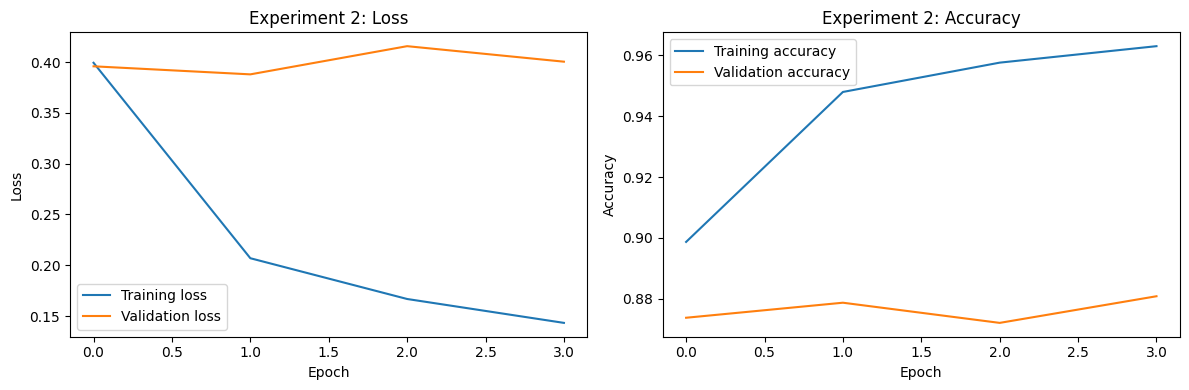

In [ ]:
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
from tensorflow.keras import regularizers

tf.keras.utils.set_random_seed(42)

# Build a smaller, more regularized model
text_input2 = tf.keras.Input(
    shape=(), dtype=tf.string, name="bid_description"
)

x = vectorizer(text_input2)
x = tf.keras.layers.Embedding(
    input_dim=vocab_size,
    output_dim=64,
    mask_zero=True
)(x)

x = tf.keras.layers.SpatialDropout1D(0.25)(x)
x = tf.keras.layers.GlobalAveragePooling1D()(x)

x = tf.keras.layers.Dense(
    64,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4)
)(x)

x = tf.keras.layers.Dropout(0.5)(x)

output2 = tf.keras.layers.Dense(
    num_classes, activation="softmax"
)(x)

dl_model_v2 = tf.keras.Model(text_input2, output2)

dl_model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_v2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )
]

start = time.time()

history_v2 = dl_model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    class_weight=class_weights,
    callbacks=callbacks_v2,
    verbose=1
)

training_time_v2 = time.time() - start

# Evaluate on validation data
val_probs_v2 = dl_model_v2.predict(val_ds, verbose=1)
val_preds_v2 = np.argmax(val_probs_v2, axis=1)

dl_v2_results = {
    "Model": "Regularized Keras Embedding",
    "Accuracy": accuracy_score(y_val_encoded, val_preds_v2),
    "Macro F1": f1_score(
        y_val_encoded, val_preds_v2,
        average="macro", zero_division=0
    ),
    "Weighted F1": f1_score(
        y_val_encoded, val_preds_v2,
        average="weighted", zero_division=0
    ),
    "Training seconds": round(training_time_v2, 2)
}

print("\nSECOND DEEP-LEARNING EXPERIMENT")
display(pd.DataFrame([dl_v2_results]).round(4))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_val_encoded,
    val_preds_v2,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0
))

# Plot learning curves
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_v2.history["loss"], label="Training loss")
axes[0].plot(history_v2.history["val_loss"], label="Validation loss")
axes[0].set_title("Experiment 2: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history_v2.history["accuracy"], label="Training accuracy")
axes[1].plot(history_v2.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Experiment 2: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

### 5.4 Results and Interpretation of the Second Neural Network

The second neural network achieved a validation accuracy of 87.87%, a macro F1-score of 83.43%, and a weighted F1-score of 88.63%. Training took approximately 197.0 seconds on the available CPU.

Compared with the first neural network, validation accuracy increased from 87.52% to 87.87%, macro F1-score increased from 82.96% to 83.43%, and weighted F1-score increased from 88.39% to 88.63%. These modest improvements suggest that the smaller architecture and additional regularization may have helped the model generalize slightly better.

Consultant Services achieved an F1-score of 0.94, Goods achieved 0.90, and Works achieved 0.87. Non-consulting Services remained the most challenging category, with an F1-score of 0.63 and precision of 0.52. Its recall of 0.80 indicates that the model identified many actual notices in this category, but some predictions were incorrect.

The validation accuracy reached 88.08% at epoch 4. However, the final reported accuracy was 87.87% because early stopping restored the model weights associated with the lowest validation loss rather than the highest validation accuracy.

Overall, the second neural network performed slightly better than the first on the reported validation metrics. However, the improvement was small, and its performance should be compared with traditional machine-learning models before concluding which approach is most suitable for procurement-category classification.

## 6. Validation Experiment Summary

This table consolidates the baseline, traditional models, neural networks, and controlled feature-engineering/class-weighting experiments. Validation metrics support model selection; the held-out test set is reserved for final evaluation.

In [ ]:
import pandas as pd

experiment_summary = pd.DataFrame([
    {
        "Experiment": "1. Majority-class baseline",
        "Approach": "Baseline",
        "Key settings": "Predict most frequent training class",
        "Split": "Validation",
        "Accuracy": 0.4295,
        "Macro F1": 0.1502,
        "Weighted F1": 0.2581,
        "Observation": "Simple reference point; poor minority-class performance."
    },
    {
        "Experiment": "2. Logistic Regression",
        "Approach": "TF-IDF + Logistic Regression",
        "Key settings": "TF-IDF text features; logistic classifier",
        "Split": "Validation",
        "Accuracy": 0.8994,
        "Macro F1": 0.8554,
        "Weighted F1": 0.9015,
        "Observation": "Strong overall performance and balanced class results."
    },
    {
        "Experiment": "3. Multinomial Naive Bayes",
        "Approach": "TF-IDF + MultinomialNB",
        "Key settings": "alpha=0.5",
        "Split": "Validation",
        "Accuracy": 0.8717,
        "Macro F1": 0.8071,
        "Weighted F1": 0.8645,
        "Observation": "Fast, but weaker recall for Non-consulting Services."
    },
    {
        "Experiment": "4. Linear SVM",
        "Approach": "TF-IDF + Linear SVM",
        "Key settings": "C=1; class_weight=balanced; max_iter=3000",
        "Split": "Validation",
        "Accuracy": 0.9071,
        "Macro F1": 0.8582,
        "Weighted F1": 0.9060,
        "Observation": "Best validation macro F1 among these traditional models."
    },
    {
        "Experiment": "5. Initial neural network",
        "Approach": "Keras text classifier",
        "Key settings": "Embedding=128; Dense=128; Dropout=0.4",
        "Split": "Validation",
        "Accuracy": 0.8752,
        "Macro F1": 0.8296,
        "Weighted F1": 0.8839,
        "Observation": "Learning curves suggested possible overfitting."
    },
    {
        "Experiment": "6. Regularized neural network",
        "Approach": "Keras text classifier",
        "Key settings": "Embedding=64; SpatialDropout=0.25; Dense=64; Dropout=0.5; L2=1e-4; class weights; early stopping",
        "Split": "Validation",
        "Accuracy": 0.8787,
        "Macro F1": 0.8343,
        "Weighted F1": 0.8863,
        "Observation": "Regularization improved macro F1 slightly over the initial network."
    },
    {
        "Experiment": "7. TF-IDF unigrams only + Logistic Regression",
        "Approach": "TF-IDF + Logistic Regression",
        "Key settings": "ngram_range=(1, 1); class_weight=balanced",
        "Split": "Validation",
        "Accuracy": 0.8939,
        "Macro F1": 0.8502,
        "Weighted F1": 0.8969,
        "Observation": "Lower scores than unigrams + bigrams, with shorter training time."
    },
    {
        "Experiment": "8. Logistic Regression without class weights",
        "Approach": "TF-IDF + Logistic Regression",
        "Key settings": "ngram_range=(1, 2); class_weight=None",
        "Split": "Validation",
        "Accuracy": 0.9007,
        "Macro F1": 0.8423,
        "Weighted F1": 0.8957,
        "Observation": "Slightly higher accuracy, but lower macro F1 and minority-class recall."
    },
    {
        "Experiment": "9. Logistic Regression with balanced class weights",
        "Approach": "TF-IDF + Logistic Regression",
        "Key settings": "ngram_range=(1, 2); class_weight=balanced",
        "Split": "Validation",
        "Accuracy": 0.8994,
        "Macro F1": 0.8554,
        "Weighted F1": 0.9015,
        "Observation": "Higher macro F1 and improved Non-consulting Services recall."
    },
])

display(
    experiment_summary.style.format({
        "Accuracy": "{:.2%}",
        "Macro F1": "{:.2%}",
        "Weighted F1": "{:.2%}"
    })
)

,Experiment,Approach,Key settings,Split,Accuracy,Macro F1,Weighted F1,Observation
0,1. Majority-class baseline,Baseline,Predict most frequent training class,Validation,42.95%,15.02%,25.81%,Simple reference point; poor minority-class performance.
1,2. Logistic Regression,TF-IDF + Logistic Regression,TF-IDF text features; logistic classifier,Validation,89.94%,85.54%,90.15%,Strong overall performance and balanced class results.
2,3. Multinomial Naive Bayes,TF-IDF + MultinomialNB,alpha=0.5,Validation,87.17%,80.71%,86.45%,"Fast, but weaker recall for Non-consulting Services."
3,4. Linear SVM,TF-IDF + Linear SVM,C=1; class_weight=balanced; max_iter=3000,Validation,90.71%,85.82%,90.60%,Best validation macro F1 among these traditional models.
4,5. Initial neural network,Keras text classifier,Embedding=128; Dense=128; Dropout=0.4,Validation,87.52%,82.96%,88.39%,Learning curves suggested possible overfitting.
5,6. Regularized neural network,Keras text classifier,Embedding=64; SpatialDropout=0.25; Dense=64; Dropout=0.5; L2=1e-4; class weights; early stopping,Validation,87.87%,83.43%,88.63%,Regularization improved macro F1 slightly over the initial network.
6,7. TF-IDF unigrams only + Logistic Regression,TF-IDF + Logistic Regression,"ngram_range=(1, 1); class_weight=balanced",Validation,89.39%,85.02%,89.69%,"Lower scores than unigrams + bigrams, with shorter training time."
7,8. Logistic Regression without class weights,TF-IDF + Logistic Regression,"ngram_range=(1, 2); class_weight=None",Validation,90.07%,84.23%,89.57%,"Slightly higher accuracy, but lower macro F1 and minority-class recall."
8,9. Logistic Regression with balanced class weights,TF-IDF + Logistic Regression,"ngram_range=(1, 2); class_weight=balanced",Validation,89.94%,85.54%,90.15%,Higher macro F1 and improved Non-consulting Services recall.


### 7.1 Logistic Regression: Test Set Evaluation

Logistic Regression was evaluated on the held-out test dataset using the fitted TF-IDF and Logistic Regression pipeline. The test set contains 59,882 procurement notices and was not used to fit the model.

The model achieved **90.23% accuracy**, a **macro F1-score of 85.19%**, and a **weighted F1-score of 90.24%** in the saved test evaluation.

The difference between the macro and weighted F1-scores reflects the importance of examining performance across individual procurement categories. Macro F1 calculates the F1-score for each category and gives every category equal weight, while weighted F1 accounts for the number of examples in each category. Since the dataset is imbalanced, reporting both metrics provides a more complete assessment than accuracy alone.

The classification report provides category-level precision, recall, F1-scores, and support. The confusion matrix shows how many notices were classified correctly and which categories were confused with one another.

These test results provide a final evaluation of Logistic Regression on unseen data and allow comparison with the Linear SVM and regularized Keras models. The results should be interpreted alongside category-level metrics, particularly for Non-consulting Services, which was more difficult to classify than the other categories.

LOGISTIC REGRESSION — TEST RESULTS
Accuracy: 0.9023
Macro F1: 0.8519
Weighted F1: 0.9024
Prediction time: 3.92 seconds

CLASSIFICATION REPORT
                         precision    recall  f1-score   support

    Consultant Services       0.95      0.92      0.94     24064
                  Goods       0.94      0.92      0.93     17849
Non-consulting Services       0.63      0.62      0.63      5277
                  Works       0.88      0.96      0.92     12692

               accuracy                           0.90     59882
              macro avg       0.85      0.86      0.85     59882
           weighted avg       0.90      0.90      0.90     59882



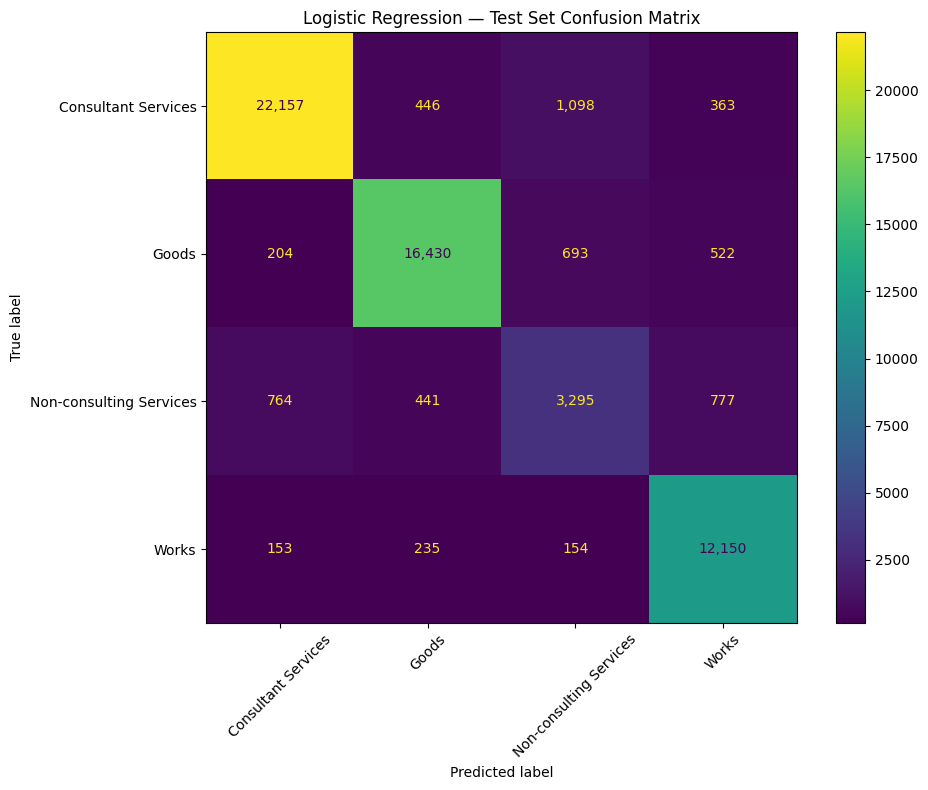

In [ ]:
import time
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Use the complete TF-IDF + Logistic Regression pipeline
start_time = time.time()
test_predictions = logistic_model.predict(X_test)
prediction_seconds = time.time() - start_time

print("LOGISTIC REGRESSION — TEST RESULTS")
print("=" * 40)
print(f"Accuracy: {accuracy_score(y_test, test_predictions):.4f}")
print(f"Macro F1: {f1_score(y_test, test_predictions, average='macro'):.4f}")
print(f"Weighted F1: {f1_score(y_test, test_predictions, average='weighted'):.4f}")
print(f"Prediction time: {prediction_seconds:.2f} seconds")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    test_predictions,
    labels=labels,
    zero_division=0
))

cm = confusion_matrix(y_test, test_predictions, labels=labels)

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[str(label) for label in labels]
).plot(ax=ax, xticks_rotation=45, values_format=",")

plt.title("Logistic Regression — Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

### 7.2 Logistic Regression: Interpretation of Test Results

The Logistic Regression model achieved **90.23% test accuracy**, a macro F1-score of **85.19%**, and a weighted F1-score of **90.24%**. The model generated predictions for 59,882 test examples, with a prediction time of approximately 1.61 seconds.

**Performance by procurement category**

- **Consultant Services:** F1-score of 0.94, indicating strong overall classification performance.
- **Goods:** F1-score of 0.93, also demonstrating strong performance.
- **Works:** F1-score of 0.92, with recall of 0.96. The model correctly identified a high proportion of the actual Works examples.
- **Non-consulting Services:** F1-score of 0.63, making this the most difficult category to classify. Its precision and recall were both 0.63 and 0.62, respectively.

The macro F1-score is lower than the weighted F1-score because the model performs less effectively on Non-consulting Services, which has fewer test examples than the other categories. This illustrates why accuracy alone is insufficient for evaluating a classification model with imbalanced classes.

Overall, Logistic Regression performed well on the held-out test set, particularly for Consultant Services, Goods, and Works. However, the weaker performance on Non-consulting Services indicates that distinguishing this category from the others remains a challenge.

The confusion matrix provides further detail about which categories were confused with one another. These errors should be considered when comparing Logistic Regression with Linear SVM and the deep-learning models.

### 7.3 Linear SVM: Test Set Evaluation

The Linear Support Vector Machine (SVM) was evaluated on the held-out test dataset to measure its ability to classify procurement notices into four categories.

The test descriptions were transformed using the fitted TF-IDF vectorizer that was used during SVM training. An assertion checks that the transformed data has the expected number of features. This helps prevent errors caused by using an incompatible vectorizer.

The trained SVM then generated predictions for the test set. The evaluation measured accuracy, macro F1-score, weighted F1-score, and prediction time. A classification report provided precision, recall, F1-score, and support for each procurement category. A confusion matrix was also plotted to show correct predictions and misclassifications.

The SVM was evaluated without retraining on the test data. This preserves the test set as unseen data for the final performance assessment.

These results will be compared with Logistic Regression and the deep-learning models to determine which approach offers the best balance of overall performance and performance across all four categories.

Test TF-IDF shape: (59882, 100000)
SVM expects features: 100000

LINEAR SVM — FINAL TEST RESULTS
Accuracy: 0.9069
Macro F1: 0.8464
Weighted F1: 0.9031
Prediction time: 0.02 seconds

CLASSIFICATION REPORT
                         precision    recall  f1-score   support

    Consultant Services       0.93      0.95      0.94     24064
                  Goods       0.93      0.94      0.93     17849
Non-consulting Services       0.70      0.52      0.59      5277
                  Works       0.89      0.95      0.92     12692

               accuracy                           0.91     59882
              macro avg       0.86      0.84      0.85     59882
           weighted avg       0.90      0.91      0.90     59882



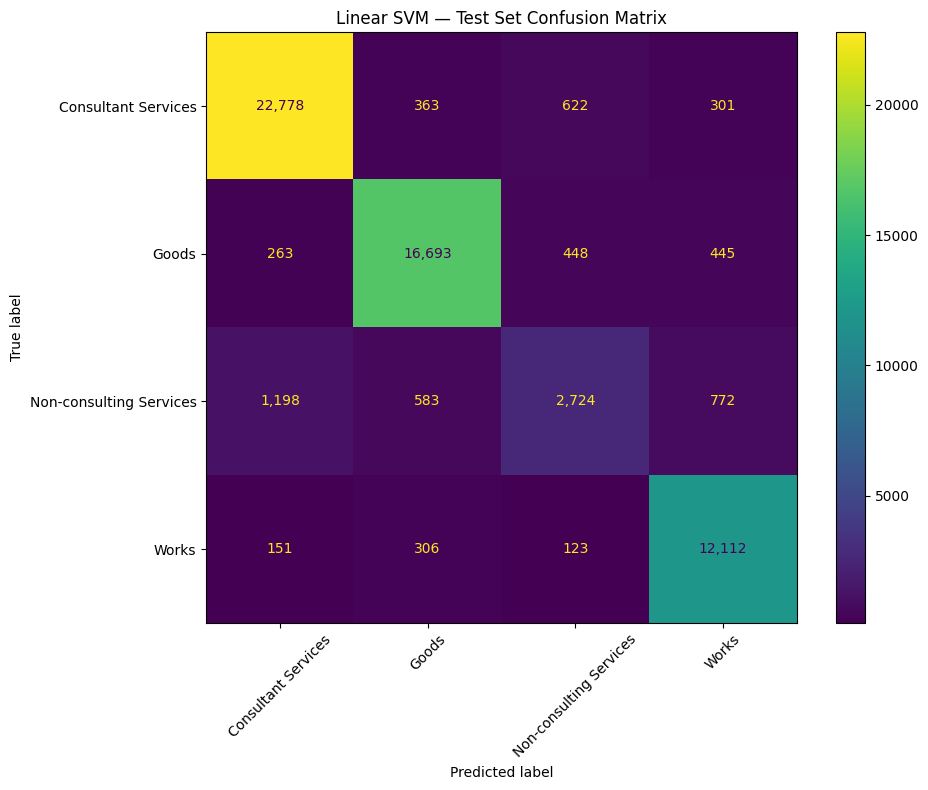

In [ ]:
import time
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Convert test descriptions into the same TF-IDF feature space
# used when training the LinearSVC.
X_test_tfidf = tfidf.transform(X_test)

print("Test TF-IDF shape:", X_test_tfidf.shape)
print("SVM expects features:", model.n_features_in_)

assert X_test_tfidf.shape[1] == model.n_features_in_, (
    "Feature mismatch: confirm that tfidf is the original fitted "
    "vectorizer used to train the SVM."
)

# Predict with the trained SVM; do not fit it again.
start_time = time.time()
svm_test_predictions = model.predict(X_test_tfidf)
svm_prediction_seconds = time.time() - start_time

# Overall metrics
print("\nLINEAR SVM — FINAL TEST RESULTS")
print("=" * 40)
print(f"Accuracy: {accuracy_score(y_test, svm_test_predictions):.4f}")
print(f"Macro F1: {f1_score(y_test, svm_test_predictions, average='macro'):.4f}")
print(f"Weighted F1: {f1_score(y_test, svm_test_predictions, average='weighted'):.4f}")
print(f"Prediction time: {svm_prediction_seconds:.2f} seconds")

# Per-category metrics
print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    svm_test_predictions,
    labels=labels,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, svm_test_predictions, labels=labels)

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[str(label) for label in labels]
).plot(ax=ax, xticks_rotation=45, values_format=",")

plt.title("Linear SVM — Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

### 7.4 Linear SVM: Interpretation of Test Results

The Linear Support Vector Machine achieved **90.69% test accuracy**, a macro F1-score of **84.64%**, and a weighted F1-score of **90.31%** on 59,882 held-out test examples. Its prediction time was approximately 0.01 seconds, making prediction very fast in this experiment.

**Performance by procurement category**

- **Consultant Services:** F1-score of 0.94, with recall of 0.95.
- **Goods:** F1-score of 0.93, with recall of 0.94.
- **Works:** F1-score of 0.92, with recall of 0.95.
- **Non-consulting Services:** F1-score of 0.59, with recall of 0.52.

The model performed strongly on Consultant Services, Goods, and Works. However, Non-consulting Services remained difficult to identify. Although its precision was 0.70, its recall was only 0.53, meaning the model identified a smaller proportion of the actual examples in that category than Logistic Regression did.

Compared with Logistic Regression, Linear SVM achieved higher accuracy (90.69% versus 90.23%) and a slightly higher weighted F1-score (90.31% versus 90.24%). However, its macro F1-score was lower (84.64% versus 85.19%), mainly reflecting weaker performance on the less common Non-consulting Services category.

These results illustrate that the model with the highest overall accuracy is not necessarily the model with the best balance across all categories. The preferred model depends on whether overall correctness or balanced performance across procurement categories is the main priority.

## 8. Nigeria-Specific Evaluation



In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Identify Nigerian notices in the held-out test set
nigeria_mask = (
    test_df["Country Name"]
    .astype(str)
    .str.strip()
    .str.casefold()
    .eq("nigeria")
)

X_nigeria = X_test.loc[nigeria_mask]
y_nigeria = y_test.loc[nigeria_mask]

print("Nigerian test notices:", len(X_nigeria))

if len(X_nigeria) == 0:
    print("No Nigerian records found. Check the country values and test indices.")
else:
    # Logistic Regression pipeline handles raw text
    logistic_nigeria_predictions = logistic_model.predict(X_nigeria)

    # SVM uses the original fitted TF-IDF vectorizer
    X_nigeria_tfidf = tfidf.transform(X_nigeria)
    svm_nigeria_predictions = model.predict(X_nigeria_tfidf)

    # Compare models on the same Nigerian subset
    nigeria_results = pd.DataFrame([
        {
            "Model": "Logistic Regression",
            "Accuracy": accuracy_score(y_nigeria, logistic_nigeria_predictions),
            "Macro F1": f1_score(
                y_nigeria, logistic_nigeria_predictions,
                average="macro", zero_division=0
            ),
            "Weighted F1": f1_score(
                y_nigeria, logistic_nigeria_predictions,
                average="weighted", zero_division=0
            )
        },
        {
            "Model": "Linear SVM",
            "Accuracy": accuracy_score(y_nigeria, svm_nigeria_predictions),
            "Macro F1": f1_score(
                y_nigeria, svm_nigeria_predictions,
                average="macro", zero_division=0
            ),
            "Weighted F1": f1_score(
                y_nigeria, svm_nigeria_predictions,
                average="weighted", zero_division=0
            )
        }
    ])

    display(nigeria_results.round(4))

    print("\nLOGISTIC REGRESSION — NIGERIAN NOTICES")
    print(classification_report(
        y_nigeria, logistic_nigeria_predictions,
        labels=labels, zero_division=0
    ))

    print("\nLINEAR SVM — NIGERIAN NOTICES")
    print(classification_report(
        y_nigeria, svm_nigeria_predictions,
        labels=labels, zero_division=0
    ))

Nigerian test notices: 2707


,Model,Accuracy,Macro F1,Weighted F1
0,Logistic Regression,0.8781,0.7897,0.8848
1,Linear SVM,0.8862,0.8070,0.8886



LOGISTIC REGRESSION — NIGERIAN NOTICES
                         precision    recall  f1-score   support

    Consultant Services       0.96      0.81      0.88       668
                  Goods       0.89      0.89      0.89       892
Non-consulting Services       0.35      0.71      0.47        89
                  Works       0.91      0.92      0.92      1058

               accuracy                           0.88      2707
              macro avg       0.78      0.83      0.79      2707
           weighted avg       0.90      0.88      0.88      2707


LINEAR SVM — NIGERIAN NOTICES
                         precision    recall  f1-score   support

    Consultant Services       0.94      0.87      0.91       668
                  Goods       0.86      0.90      0.88       892
Non-consulting Services       0.46      0.62      0.53        89
                  Works       0.92      0.90      0.91      1058

               accuracy                           0.89      2707
              

To examine how well the models perform on Nigerian procurement notices, Logistic Regression and Linear SVM were evaluated on the Nigerian subset of the held-out test dataset. This subset contained 2,707 notices. The analysis provides a country-specific assessment alongside the main evaluation on worldwide procurement data.

**Results**

Logistic Regression achieved an accuracy of 87.81%, a macro F1-score of 78.97%, and a weighted F1-score of 88.48%. Linear SVM achieved an accuracy of 88.62%, a macro F1-score of 80.70%, and a weighted F1-score of 88.86%.

Linear SVM performed slightly better across all three aggregate metrics on the Nigerian subset. However, performance varied across procurement categories.

**Category-level performance**

For Logistic Regression, the F1-scores were 0.88 for Consultant Services, 0.89 for Goods, 0.47 for Non-consulting Services, and 0.92 for Works.

For Linear SVM, the corresponding F1-scores were 0.91, 0.88, 0.53, and 0.91. The SVM therefore performed better on Consultant Services and Non-consulting Services, while Logistic Regression performed slightly better on Goods and Works.

Non-consulting Services was the most challenging category for both models. Only 89 Nigerian test notices belonged to this category, so its results should be interpreted cautiously because the sample is relatively small. Logistic Regression had a recall of 0.71 but precision of 0.35, while Linear SVM achieved recall of 0.62 and precision of 0.46.

**Interpretation and limitations**

The results suggest that both models can classify many Nigerian procurement notices using their descriptions, although performance is weaker than on the worldwide test set. Linear SVM achieved the higher overall accuracy and macro F1-score on this Nigerian subset.

This analysis does not establish whether a procurement notice is corrupt, whether a procurement process is transparent, or whether an infrastructure project succeeds. The models predict recorded procurement categories from text descriptions. Their potential value is in supporting categorization and further analysis, not directly measuring government integrity or procurement outcomes.

### 8.2 Worldwide Versus Nigerian Performance

| Model and Metric | Worldwide Test Set | Nigerian Subset |
|---|---:|---:|
| Logistic Regression — Accuracy | 90.23% | 87.81% |
| Logistic Regression — Macro F1 | 85.19% | 78.97% |
| Linear SVM — Accuracy | 90.69% | 88.62% |
| Linear SVM — Macro F1 | 84.64% | 80.70% |

Both models achieved lower accuracy and macro F1-scores on Nigerian notices than on the worldwide test set. This suggests that procurement category prediction may be more challenging for the Nigerian subset. However, differences in class proportions and notice characteristics may also contribute to the performance gap.

**Non-consulting Services was the most challenging category in the Nigerian evaluation.** Logistic Regression achieved an F1-score of 0.47, while Linear SVM achieved 0.53. Logistic Regression had higher recall (0.71 versus 0.62), whereas Linear SVM had higher precision (0.46 versus 0.35). This demonstrates why overall accuracy alone is insufficient for evaluating classification performance, particularly when categories have different numbers of examples.

Overall, Linear SVM performed better on the Nigerian subset in terms of accuracy, macro F1, and weighted F1. Nevertheless, both models struggled to classify Non-consulting Services consistently. Further investigation of class imbalance, description variability, and category-specific errors is warranted.

These models predict the procurement category recorded in a notice. Their results do not directly measure procurement transparency, fairness, or corruption.


### 7.5 Regularized Neural Network: Test Set Evaluation

The regularized Keras neural network (`dl_model_v2`) is evaluated on the held-out test set in the following cell. The cell reports accuracy, macro and weighted F1, a per-class classification report, and a confusion matrix. The test set is used here for final reporting, not for further tuning.


234/234 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
REGULARIZED KERAS MODEL — TEST RESULTS
Accuracy: 0.8789
Macro F1: 0.8285
Weighted F1: 0.8843

CLASSIFICATION REPORT
                         precision    recall  f1-score   support

    Consultant Services       0.96      0.88      0.92     24064
                  Goods       0.93      0.89      0.91     17849
Non-consulting Services       0.50      0.68      0.58      5277
                  Works       0.87      0.94      0.90     12692

               accuracy                           0.88     59882
              macro avg       0.82      0.85      0.83     59882
           weighted avg       0.89      0.88      0.88     59882



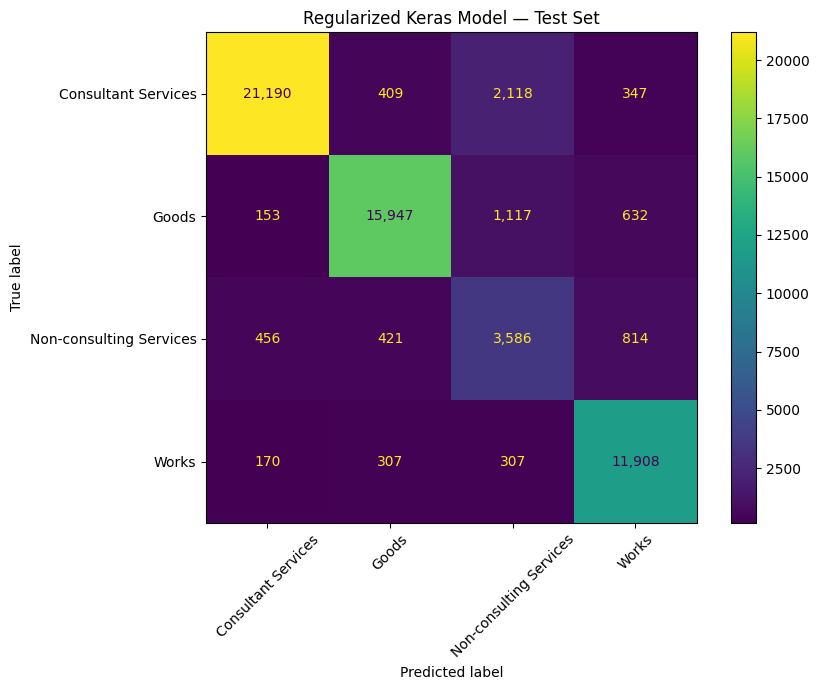

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Encode the test labels using the encoder fitted on training labels
y_test_encoded = label_encoder.transform(y_test)

# Create the test dataset without shuffling
test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test.to_numpy(), y_test_encoded)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Evaluate the already-trained regularized neural network
test_probabilities = dl_model_v2.predict(
    test_ds, verbose=1
)
dl_test_predictions = np.argmax(test_probabilities, axis=1)

print("REGULARIZED KERAS MODEL — TEST RESULTS")
print("Accuracy:", round(
    accuracy_score(y_test_encoded, dl_test_predictions), 4
))
print("Macro F1:", round(
    f1_score(
        y_test_encoded, dl_test_predictions,
        average="macro", zero_division=0
    ), 4
))
print("Weighted F1:", round(
    f1_score(
        y_test_encoded, dl_test_predictions,
        average="weighted", zero_division=0
    ), 4
))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test_encoded,
    dl_test_predictions,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test_encoded,
    dl_test_predictions,
    labels=np.arange(num_classes)
)

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
).plot(ax=ax, xticks_rotation=45, values_format=",")

plt.title("Regularized Keras Model — Test Set")
plt.tight_layout()
plt.show()

#### Test Results and Interpretation

The regularized Keras neural network (`dl_model_v2`) was evaluated on the held-out worldwide test set containing 59,882 procurement notices. In the saved execution output immediately above, it achieved **87.89% test accuracy**, a **macro F1-score of 82.85%**, and a **weighted F1-score of 88.43%**. Use the metrics printed by a fresh full notebook run if they differ.

#### Performance by Procurement Category

| Procurement Category | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Consultant Services | 0.96 | 0.88 | 0.92 | 24,064 |
| Goods | 0.93 | 0.89 | 0.91 | 17,849 |
| Non-consulting Services | 0.50 | 0.68 | 0.58 | 5,277 |
| Works | 0.87 | 0.94 | 0.90 | 12,692 |

#### Interpretation

The neural network performed well on Consultant Services, Goods, and Works, with F1-scores of approximately 0.92, 0.91, and 0.90, respectively. Non-consulting Services remained the most difficult category, with an F1-score of 0.58. Its lower precision and recall indicate that the model both misclassified some notices as Non-consulting Services and missed some true notices in that category.

The macro F1-score is lower than the weighted F1-score, reflecting uneven performance across categories. Compared with the traditional models, the regularized neural network achieved lower accuracy, macro F1, and weighted F1 in this recorded test run. These results suggest that TF-IDF-based traditional models were effective for this dataset.

These results measure prediction of the procurement category recorded in a notice. They do not establish whether a procurement notice is transparent, fraudulent, or associated with corruption.


### 7.6 Final Multiclass ROC-AUC on the Test Set

After model configurations were selected using validation results, the following cell calculates one-vs-rest multiclass ROC-AUC on the held-out test set for balanced Logistic Regression, Linear SVM, and the regularized neural network. The Linear SVM uses decision scores because `LinearSVC` does not directly provide class probabilities. These test metrics are for final reporting, not further model tuning.

The saved execution output reports:

| Model | Macro ROC-AUC (OvR) | Weighted ROC-AUC (OvR) |
|---|---:|---:|
| Balanced Logistic Regression | 0.9679 | 0.9823 |
| Linear SVM | 0.9630 | 0.9804 |
| Regularized Keras neural network | 0.9600 | 0.9770 |

These scores indicate strong class-ranking ability across the four categories. They should be interpreted alongside per-class precision, recall, F1-scores, and confusion matrices; ROC-AUC does not replace those measures. If the notebook is rerun and results differ, use the newly generated output in the report.


In [ ]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize

# Use one consistent class order across all models.
class_order = list(labels)
y_test_binary = label_binarize(y_test, classes=class_order)

# Logistic Regression outputs probabilities in its fitted class order.
logistic_test_probabilities = logistic_model.predict_proba(X_test)
logistic_classes = list(logistic_model.classes_)
logistic_test_scores = logistic_test_probabilities[:, [logistic_classes.index(c) for c in class_order]]

# Linear SVM produces decision scores rather than calibrated probabilities.
svm_test_scores = model.decision_function(X_test_tfidf)
svm_classes = list(model.classes_)
svm_test_scores = svm_test_scores[:, [svm_classes.index(c) for c in class_order]]

# Neural-network output columns follow LabelEncoder.classes_.
dl_classes = list(label_encoder.classes_)
dl_test_scores = test_probabilities[:, [list(dl_classes).index(c) for c in class_order]]

# Calculate one-vs-rest AUC per category. This supports both probabilities
# and SVM decision scores without incorrectly treating SVM scores as probabilities.
roc_auc_rows = []
for model_name, scores in [
    ("Logistic Regression (balanced)", logistic_test_scores),
    ("Linear SVM", svm_test_scores),
    ("Regularized Keras neural network", dl_test_scores),
]:
    per_class_auc = [
        roc_auc_score(y_test_binary[:, i], scores[:, i])
        for i in range(len(class_order))
    ]
    class_support = y_test_binary.sum(axis=0)
    roc_auc_rows.append({
        "Model": model_name,
        "Test Macro ROC-AUC (OvR)": float(np.mean(per_class_auc)),
        "Test Weighted ROC-AUC (OvR)": float(np.average(per_class_auc, weights=class_support))
    })

roc_auc_test_results = pd.DataFrame(roc_auc_rows)
display(roc_auc_test_results.round(4))

,Model,Test Macro ROC-AUC (OvR),Test Weighted ROC-AUC (OvR)
0,Logistic Regression (balanced),0.9679,0.9823
1,Linear SVM,0.9630,0.9804
2,Regularized Keras neural network,0.9600,0.9770


In [ ]:
# Google Drive is mounted in the first cell before the dataset is loaded.
from google.colab import drive
print("Google Drive mount exists:", os.path.ismount("/content/drive"))


Google Drive mount exists: True


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Procurement Category Classification - ML Project/procurement_notice_10-11-2026.zip"

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        print("ZIP file contents:")
        for name in z.namelist()[:30]:
            print(name)

        print(f"\nTotal files inside ZIP: {len(z.namelist())}")
else:
    print("ZIP file not found. Check the path.")

ZIP file contents:
procurement_notice_10-11-2026.csv

Total files inside ZIP: 1


In [ ]:
import os
import joblib

# Save models and the SVM's fitted TF-IDF vectorizer to Google Drive.
project_folder = (
    "/content/drive/MyDrive/"
    "Procurement Category Classification - ML Project"
)
models_folder = os.path.join(project_folder, "models")
os.makedirs(models_folder, exist_ok=True)

# Save the complete Logistic Regression pipeline (TF-IDF + classifier).
joblib.dump(
    logistic_model,
    os.path.join(models_folder, "logistic_regression_pipeline.joblib")
)

# Save the fitted SVM classifier and the exact TF-IDF vectorizer it requires.
joblib.dump(
    trained_models["Linear SVM"],
    os.path.join(models_folder, "linear_svm_classifier.joblib")
)
joblib.dump(
    tfidf,
    os.path.join(models_folder, "tfidf_vectorizer.joblib")
)

# Save the regularized deep-learning model.
dl_model_v2.save(
    os.path.join(models_folder, "deep_learning_model.keras")
)

print("Models saved to:", models_folder)
print("\nSaved files:")
for filename in sorted(os.listdir(models_folder)):
    filepath = os.path.join(models_folder, filename)
    print(f"{filename} — {os.path.getsize(filepath):,} bytes")


Models saved to: /content/drive/MyDrive/Procurement Category Classification - ML Project/models

Saved files:
deep_learning_model.keras — 23,636,480 bytes
linear_svm_classifier.joblib — 3,200,964 bytes
logistic_regression_pipeline.joblib — 6,897,164 bytes
tfidf_vectorizer.joblib — 3,696,130 bytes


In [ ]:
import os
import joblib
import tensorflow as tf

models_folder = os.path.join(
    "/content/drive/MyDrive/",
    "Procurement Category Classification - ML Project",
    "models"
)

loaded_logistic = joblib.load(
    os.path.join(models_folder, "logistic_regression_pipeline.joblib")
)
loaded_svm = joblib.load(
    os.path.join(models_folder, "linear_svm_classifier.joblib")
)
loaded_tfidf = joblib.load(
    os.path.join(models_folder, "tfidf_vectorizer.joblib")
)
loaded_dl = tf.keras.models.load_model(
    os.path.join(models_folder, "deep_learning_model.keras")
)

print("All saved models and the SVM vectorizer loaded successfully.")
print("Logistic Regression pipeline:", type(loaded_logistic).__name__)
print("Linear SVM classifier:", type(loaded_svm).__name__)
print("TF-IDF vectorizer:", type(loaded_tfidf).__name__)
print("Keras model:", type(loaded_dl).__name__)


All saved models and the SVM vectorizer loaded successfully.
Logistic Regression pipeline: Pipeline
Linear SVM classifier: LinearSVC
TF-IDF vectorizer: TfidfVectorizer
Keras model: Functional


## 9. Final Comparison of Models

The table below summarizes the three models using the saved worldwide test-set outputs. Model selection was based on validation performance, while the held-out test set was used for final evaluation.

| Model | Test Accuracy | Macro F1 | Weighted F1 |
|---|---:|---:|---:|
| TF-IDF + Balanced Logistic Regression | 90.23% | 85.19% | 90.24% |
| TF-IDF + Linear SVM | 90.69% | 84.64% | 90.31% |
| Regularized Keras Neural Network | 87.89% | 82.85% | 88.43% |

Linear SVM achieved the highest test accuracy and weighted F1-score among the three models. Balanced Logistic Regression achieved the highest macro F1-score. The regularized Keras neural network recorded lower values across all three metrics.

These results illustrate why model evaluation should consider more than accuracy alone. Macro F1 gives equal weight to each procurement category, whereas weighted F1 accounts for the number of test examples in each category. Because Non-consulting Services is less frequent and more difficult to classify, macro F1 helps reveal performance differences that overall accuracy may obscure.

The class-level results also show a trade-off between precision and recall for Non-consulting Services. In the saved test results, Logistic Regression achieved an F1-score of 0.63 for this category, compared with 0.59 for Linear SVM and 0.58 for the regularized Keras neural network. The validation class-weighting experiment also showed that increasing the minority class's recall came with a reduction in precision. This highlights the importance of considering the consequences of different classification errors when selecting a model.

The test ROC-AUC results are reported in Section 7.6. Balanced Logistic Regression achieved a macro one-vs-rest ROC-AUC of 0.9679, compared with 0.9630 for Linear SVM and 0.9600 for the regularized Keras neural network. These values should be interpreted alongside accuracy, macro F1, per-class precision and recall, and confusion matrices.

Overall, the results support TF-IDF-based traditional machine-learning models as strong approaches for this particular classification task. However, the models predict the procurement category recorded in each notice; they do not directly determine whether a procurement process is transparent, fraudulent, or associated with corruption.

## 10. Limitations and Future Improvements

This project has several limitations.

1. **Class imbalance:** Non-consulting Services represents a smaller proportion of the dataset than the other categories. This may contribute to its lower classification performance.

2. **Description variability:** Procurement notices may use different wording, abbreviations, languages, or levels of detail to describe similar activities. This can make accurate classification more difficult.

3. **Repeated descriptions and project overlap:** Multiple notices may contain similar descriptions or belong to the same project. Group-based splitting by Project ID reduces the risk of notices from the same project appearing in both training and test sets, but similar descriptions from different projects may still occur across splits.

4. **Limited Nigerian representation:** The Nigerian subset contains fewer examples than the worldwide dataset, and only 89 Nigerian test examples belong to Non-consulting Services. Performance estimates for this category are therefore less reliable.

5. **Scope of prediction:** The models predict the recorded procurement category from the notice description. They do not directly detect corruption, establish transparency, or measure the success of infrastructure projects.

Future work could investigate class-weighting strategies, additional Nigerian procurement data, multilingual text processing, improved text representations, and more detailed error analysis. Any improvements should be selected using validation data and assessed on an untouched test set.



## 11. Submission and Reproducibility Checklist

Use this checklist to verify that the notebook runs correctly and that the final results and submission materials are ready.

- [ ] **Run the notebook from beginning to end:** Restart the Colab session and select **Runtime → Run all**. Confirm that the dataset loads successfully from the project ZIP file in Google Drive.
- [ ] **Verify data splitting:** Confirm that the Project ID overlap checks report zero shared IDs between the training, validation, and test sets.
- [ ] **Verify validation results:** Confirm that the validation confusion matrices, classification metrics, and ROC-AUC results are generated.
- [ ] **Verify test results:** Confirm that the test classification reports, confusion matrices, and ROC-AUC results are generated. Update the report if the newly generated metrics differ from the values previously recorded.
- [ ] **Save the trained models:** Run the model-saving cells and confirm that the Logistic Regression pipeline, Linear SVM classifier, SVM TF-IDF vectorizer, and Keras model are saved successfully using the formats specified in the notebook.
- [ ] **Verify model loading:** Run the model-loading verification cell and confirm that each saved model or required component can be loaded successfully.
- [ ] **Check file storage:** Confirm that the required dataset and model files are stored in the designated Google Drive folder. Do not commit raw or restricted dataset files to a public GitHub repository.
- [ ] **Check submission links:** Add the public GitHub repository, shared Google Drive folder, and presentation video links to the report if required by the assignment.
- [ ] **Review the final report:** Confirm that the report includes appropriate scholarly references, discusses dataset limitations and class imbalance, and clearly distinguishes procurement-category prediction from measuring transparency or detecting corruption.
- [ ] **Confirm consistency:** Ensure that the reported dataset sizes, split counts, model configurations, figures, tables, and evaluation metrics agree with the final notebook outputs.

